# Transductive Adaptation of Riemannian Baselines (LOSO)

## 1. Objective
Notebook `09_Riemannian_baselines_LOSO` used **no test-time adaptation**: every pipeline was fitted on the training subjects and applied to the held-out subject without looking at its data. This notebook runs the separate, **transductive** experiment that was deliberately left out:

> Does re-estimating the covariance reference on the *unlabeled* data of the target subject (tangent-space reference update, or Riemannian recentering of the covariances) improve cross-subject decoding of 4-class motor imagery?

Cross-subject EEG differences are largely a shift in the *mean covariance* of each subject. Aligning every subject to a common reference (the identity matrix) is therefore a natural and cheap fix for the Riemannian pipelines.

## 2. Why this must be reported separately
All adaptations below use the **unlabeled test-subject trials at inference time**. Labels of the test subject are never used, but the test data are no longer completely unseen. The results are therefore **not comparable one-to-one** with the inductive neural networks of `9_0`/`9_1`, which never see the target subject before prediction. The comparison section states this explicitly.

## 3. Adaptation variants
Notation: `C` = Ledoit-Wolf covariance of a trial, `M_s` = Riemannian mean of the covariances of subject `s` (labels not needed).

| Adaptation | Models | What changes |
|---|---|---|
| `static` | MDM, TS-LR | Reference baseline, identical to notebook 09 (no adaptation) |
| `tsupdate` | TS-LR | Tangent-space reference is re-estimated as the mean of the test batch (`tsupdate=True`); the classifier is trained on training tangent vectors only |
| `RA-full` | MDM, TS-LR | **Riemannian Alignment**: every subject (training, validation and test) is recentered with its own mean, `C -> M_s^(-1/2) C M_s^(-1/2)`. The target mean is estimated on **all** its unlabeled trials (offline) |
| `RA-calib48` | MDM, TS-LR | Same as `RA-full`, but the target mean is estimated only from the **first 48 trials** (12 per class on average, chronological order), a more realistic short unlabeled calibration. All trials are still predicted, including the 48 calibration ones (unlabeled) |

Training subjects are recentered with their own full unlabeled data in all `RA-*` variants (they are sources, so this is legitimate). Hyper-parameters are fixed a priori (`C=1.0`), no tuning on test subjects, no augmentation. The two normalizations (`none`, `zscore`) of notebook 09 are kept.

The validation subject is processed exactly like a test subject (same adaptation, never used for fitting) and its score is stored, so any variant selection can be made on validation only.

## Setup, path check and constants

In [4]:
%pip install -q pyriemann

Note: you may need to restart the kernel to use updated packages.


In [5]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

from scipy.stats import wilcoxon
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report

import pyriemann
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace
from pyriemann.classification import MDM

# pyRiemann >= 0.12 moved these helpers; fall back to the old location for older versions
try:
    from pyriemann.geometry.mean import mean_covariance
    from pyriemann.geometry.base import invsqrtm
except ImportError:
    from pyriemann.utils.mean import mean_covariance
    from pyriemann.utils.base import invsqrtm

print(f"pyRiemann {pyriemann.__version__} | MNE {mne.__version__}")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.makedirs('saved_plots', exist_ok=True)

CLEAN_DATA_DIR = os.path.join('.', 'cleaned_data_1_40')
EVENT_ID = {'left': 1, 'right': 2, 'foot': 3, 'tongue': 4}
CLASS_NAMES = ['Left Hand', 'Right Hand', 'Foot', 'Tongue']
LABELS = [0, 1, 2, 3]
T_MIN, T_MAX = 0.5, 3.5
ALL_SUBJECTS = [f'A{i:02d}T' for i in range(1, 10)]
NORMALIZATIONS = ['none', 'zscore']
N_CALIB = 48                                   # unlabeled trials used by RA-calib48
RESULTS_CSV = 'riemannian_transductive_loso_results.csv'
BASELINE_CSV = 'riemannian_loso_results.csv'   # output of notebook 09 (used for a consistency check)

print("Checking file paths...")
missing = [
    os.path.join(CLEAN_DATA_DIR, f"{sub}_clean_1_40_raw.fif")
    for sub in ALL_SUBJECTS
    if not os.path.exists(os.path.join(CLEAN_DATA_DIR, f"{sub}_clean_1_40_raw.fif"))
]
assert not missing, f"Missing data files: {missing}"
print("All files found.")

pyRiemann 0.12 | MNE 1.12.0
Checking file paths...
All files found.


## Data loading and covariance precomputation
Loading and normalization are identical to notebook 09. Covariance estimation is performed **per trial** and does not depend on the training set, so computing the Ledoit-Wolf covariances once per subject is exactly equivalent to putting `Covariances(estimator="lwf")` inside every pipeline, and is much faster. The time series are discarded afterwards to save memory.

For each normalization and subject three covariance sets are stored:
- `raw`: no adaptation;
- `ra_full`: recentered with the Riemannian mean of **all** the subject's trials;
- `ra_calib`: recentered with the Riemannian mean of the **first `N_CALIB` trials** only.

Trials are in chronological order, so "first `N_CALIB`" mimics a short calibration at the start of a session. No label is used to compute any mean.

In [6]:
def load_subject(subject_id):
    '''Loads one cleaned .fif file and returns epochs in microvolts (trials x channels x samples).'''
    file_path = os.path.join(CLEAN_DATA_DIR, f'{subject_id}_clean_1_40_raw.fif')
    raw = mne.io.read_raw_fif(file_path, preload=True, verbose=False)
    raw.pick(['eeg'])
    events, _ = mne.events_from_annotations(raw, event_id=EVENT_ID, verbose=False)
    epochs = mne.Epochs(raw, events, event_id=EVENT_ID, tmin=T_MIN, tmax=T_MAX,
                        baseline=None, preload=True, verbose=False)
    X = epochs.get_data(copy=True).astype(np.float64) * 1e6   # V -> µV
    y = (epochs.events[:, -1] - 1).astype(np.int64)
    return X, y


def apply_normalization(X, mode):
    '''none: unchanged. zscore: per-trial, per-channel standardization (as in the neural notebooks).'''
    if mode == 'none':
        return X
    if mode == 'zscore':
        mean = X.mean(axis=-1, keepdims=True)
        std = X.std(axis=-1, keepdims=True)
        return (X - mean) / (std + 1e-8)
    raise ValueError("normalization must be 'none' or 'zscore'")


def recenter(covs, ref_covs=None):
    '''Riemannian recentering: C -> M^(-1/2) C M^(-1/2), with M the Riemannian mean of ref_covs
    (default: covs itself). Only unlabeled covariances are used.'''
    ref = mean_covariance(covs if ref_covs is None else ref_covs, metric='riemann')
    W = invsqrtm(ref)
    out = W @ covs @ W
    return (out + out.transpose(0, 2, 1)) / 2     # remove numerical asymmetry


covs = {n: {'raw': {}, 'ra_full': {}, 'ra_calib': {}} for n in NORMALIZATIONS}
labels = {}
cov_est = Covariances(estimator='lwf')

print("Loading subjects and computing covariances...")
for sub in ALL_SUBJECTS:
    X_uv, y_sub = load_subject(sub)
    labels[sub] = y_sub
    for norm in NORMALIZATIONS:
        C = cov_est.fit_transform(apply_normalization(X_uv, norm))
        covs[norm]['raw'][sub] = C
        covs[norm]['ra_full'][sub] = recenter(C)
        covs[norm]['ra_calib'][sub] = recenter(C, ref_covs=C[:N_CALIB])
    del X_uv
print("Done.")

N_CHANS = covs['none']['raw'][ALL_SUBJECTS[0]].shape[1]
print(f"Covariance matrices: {N_CHANS} x {N_CHANS}")


def stack_c(subjects, norm, store):
    '''Concatenates covariances (and labels) of the given subjects from one store.'''
    C = np.concatenate([covs[norm][store][s] for s in subjects], axis=0)
    y = np.concatenate([labels[s] for s in subjects], axis=0)
    return C, y

Loading subjects and computing covariances...
Done.
Covariance matrices: 22 x 22


## Sanity checks
1. After full recentering, the Riemannian mean of every subject must be (numerically) the identity.
2. The calibration-based recentering must **not** be exactly identity on the full session: that difference is precisely the cost of a short calibration.
3. Quantify the cross-subject shift: Riemannian distance between subject means before and after alignment. If alignment works, the distances should collapse.

In [7]:
try:
    from pyriemann.geometry.distance import distance_riemann
except ImportError:
    from pyriemann.utils.distance import distance_riemann

I = np.eye(N_CHANS)
for norm in NORMALIZATIONS:
    dev_full = [distance_riemann(mean_covariance(covs[norm]['ra_full'][s], metric='riemann'), I)
                for s in ALL_SUBJECTS]
    dev_cal = [distance_riemann(mean_covariance(covs[norm]['ra_calib'][s], metric='riemann'), I)
               for s in ALL_SUBJECTS]
    assert max(dev_full) < 1e-3, "full recentering should give an identity mean"
    print(f"[{norm:6s}] distance of subject mean from identity | ra_full: max={max(dev_full):.2e} "
          f"| ra_calib{N_CALIB}: mean={np.mean(dev_cal):.3f}, max={max(dev_cal):.3f}")

# Cross-subject shift: mean pairwise Riemannian distance between subject means
def mean_pairwise_shift(store, norm):
    means = [mean_covariance(covs[norm][store][s], metric='riemann') for s in ALL_SUBJECTS]
    d = [distance_riemann(means[i], means[j])
         for i in range(len(means)) for j in range(i + 1, len(means))]
    return np.mean(d)

print()
for norm in NORMALIZATIONS:
    print(f"[{norm:6s}] mean pairwise distance between subject means | "
          f"before alignment: {mean_pairwise_shift('raw', norm):.3f} | "
          f"after full RA: {mean_pairwise_shift('ra_full', norm):.3f}")

[none  ] distance of subject mean from identity | ra_full: max=1.05e-12 | ra_calib48: mean=0.610, max=0.796
[zscore] distance of subject mean from identity | ra_full: max=8.86e-13 | ra_calib48: mean=0.558, max=0.781

[none  ] mean pairwise distance between subject means | before alignment: 5.466 | after full RA: 0.000
[zscore] mean pairwise distance between subject means | before alignment: 4.477 | after full RA: 0.000


## Models and adaptation configurations
Classifiers operate directly on the precomputed covariance matrices.

Each adaptation specifies the covariance store used to **fit** (`train`), the store used to **predict** the validation and test subject (`test`), and whether the tangent-space reference is updated on the test batch (`ts_update`).

In [8]:
MODELS = ["MDM", "TangentSpace_LogReg"]

# adaptation -> (train store, test store, tangent-space reference update, models it applies to)
ADAPTATIONS = {
    "static":     dict(train="raw",     test="raw",      ts_update=False, models=MODELS),
    "tsupdate":   dict(train="raw",     test="raw",      ts_update=True,  models=["TangentSpace_LogReg"]),
    "RA-full":    dict(train="ra_full", test="ra_full",  ts_update=False, models=MODELS),
    "RA-calib48": dict(train="ra_full", test="ra_calib", ts_update=False, models=MODELS),
}


def build_classifier(model_name, ts_update):
    '''Fresh, unfitted classifier operating on covariance matrices.'''
    if model_name == "MDM":
        return MDM(metric="riemann")
    return make_pipeline(
        TangentSpace(metric="riemann", tsupdate=ts_update),
        LogisticRegression(C=1.0, max_iter=2000),
    )

for name, cfg in ADAPTATIONS.items():
    print(f"{name:11s} -> {cfg}")

static      -> {'train': 'raw', 'test': 'raw', 'ts_update': False, 'models': ['MDM', 'TangentSpace_LogReg']}
tsupdate    -> {'train': 'raw', 'test': 'raw', 'ts_update': True, 'models': ['TangentSpace_LogReg']}
RA-full     -> {'train': 'ra_full', 'test': 'ra_full', 'ts_update': False, 'models': ['MDM', 'TangentSpace_LogReg']}
RA-calib48  -> {'train': 'ra_full', 'test': 'ra_calib', 'ts_update': False, 'models': ['MDM', 'TangentSpace_LogReg']}


## LOSO loop
Same folds as the neural notebooks and notebook 09. Classifiers are fitted only on the seven training subjects. Fits that are identical across adaptations (e.g. `RA-full` and `RA-calib48` share the same training data) are computed once and reused; the stored `Fit Time (s)` refers to that shared fit.

In [9]:
def fold_metrics(y_true, y_pred):
    report = classification_report(y_true, y_pred, labels=LABELS, target_names=CLASS_NAMES,
                                   output_dict=True, zero_division=0)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro Precision": report['macro avg']['precision'],
        "Macro Recall": report['macro avg']['recall'],
        "Macro F1": report['macro avg']['f1-score'],
        "Weighted Precision": report['weighted avg']['precision'],
        "Weighted Recall": report['weighted avg']['recall'],
        "Weighted F1": report['weighted avg']['f1-score'],
    }


loso_results = []
print("Starting transductive LOSO evaluation...\n")
for i, test_sub in enumerate(ALL_SUBJECTS):
    val_sub = ALL_SUBJECTS[(i + 1) % len(ALL_SUBJECTS)]
    train_subs = [s for s in ALL_SUBJECTS if s not in (test_sub, val_sub)]
    assert test_sub != val_sub and not ({test_sub, val_sub} & set(train_subs))
    print(f"Fold {i+1}/9 | Test: {test_sub} | Validation: {val_sub}")

    for norm in NORMALIZATIONS:
        for model_name in MODELS:
            fitted = {}   # (train store, ts_update) -> (classifier, fit time)

            for adapt, cfg in ADAPTATIONS.items():
                if model_name not in cfg["models"]:
                    continue

                key = (cfg["train"], cfg["ts_update"])
                if key not in fitted:
                    X_tr, y_tr = stack_c(train_subs, norm, cfg["train"])
                    clf = build_classifier(model_name, cfg["ts_update"])
                    t0 = time.time()
                    clf.fit(X_tr, y_tr)
                    fitted[key] = (clf, time.time() - t0)
                clf, fit_time = fitted[key]

                X_va, y_va = stack_c([val_sub], norm, cfg["test"])
                X_te, y_te = stack_c([test_sub], norm, cfg["test"])
                y_pred_val = clf.predict(X_va)
                y_pred_te = clf.predict(X_te)

                row = {
                    "Test Subject": test_sub,
                    "Validation Subject": val_sub,
                    "Model": model_name,
                    "Normalization": norm,
                    "Adaptation": adapt,
                    **fold_metrics(y_te, y_pred_te),
                    "Val Balanced Accuracy": balanced_accuracy_score(y_va, y_pred_val),
                    "Fit Time (s)": round(fit_time, 2),
                }
                loso_results.append(row)
                print(f"   {model_name:20s} {norm:6s} {adapt:11s} | test bal.acc = {row['Balanced Accuracy']:.3f} "
                      f"| val bal.acc = {row['Val Balanced Accuracy']:.3f}")

results_df = pd.DataFrame(loso_results)
results_df.to_csv(RESULTS_CSV, index=False)
print(f"\nLOSO evaluation finished. Detailed results saved to '{RESULTS_CSV}'.")

Starting transductive LOSO evaluation...

Fold 1/9 | Test: A01T | Validation: A02T
   MDM                  none   static      | test bal.acc = 0.253 | val bal.acc = 0.250
   MDM                  none   RA-full     | test bal.acc = 0.389 | val bal.acc = 0.274
   MDM                  none   RA-calib48  | test bal.acc = 0.403 | val bal.acc = 0.271
   TangentSpace_LogReg  none   static      | test bal.acc = 0.253 | val bal.acc = 0.278
   TangentSpace_LogReg  none   tsupdate    | test bal.acc = 0.299 | val bal.acc = 0.226
   TangentSpace_LogReg  none   RA-full     | test bal.acc = 0.330 | val bal.acc = 0.271
   TangentSpace_LogReg  none   RA-calib48  | test bal.acc = 0.312 | val bal.acc = 0.229
   MDM                  zscore static      | test bal.acc = 0.299 | val bal.acc = 0.257
   MDM                  zscore RA-full     | test bal.acc = 0.375 | val bal.acc = 0.295
   MDM                  zscore RA-calib48  | test bal.acc = 0.375 | val bal.acc = 0.306
   TangentSpace_LogReg  zscore static

## Consistency check against notebook 09
The `static` rows must reproduce the results of notebook 09 (same data, same estimator, same classifiers), up to numerical noise. If they do not, the two notebooks are not working on the same data or splits and no conclusion about adaptation should be drawn.

In [10]:
if os.path.exists(BASELINE_CSV):
    base = pd.read_csv(BASELINE_CSV).rename(columns={"Balanced Accuracy": "BA_nb09"})
    chk = results_df[results_df["Adaptation"] == "static"].merge(
        base[["Test Subject", "Model", "Normalization", "BA_nb09"]],
        on=["Test Subject", "Model", "Normalization"], how="inner")
    max_diff = (chk["Balanced Accuracy"] - chk["BA_nb09"]).abs().max()
    print(f"Compared {len(chk)} static rows with '{BASELINE_CSV}': max |difference| in balanced accuracy = {max_diff:.2e}")
    if max_diff > 1e-6:
        print("WARNING: static results differ from notebook 09. Check data, normalization and splits.")
else:
    print(f"'{BASELINE_CSV}' not found: consistency check skipped (run notebook 09 first to enable it).")

Compared 36 static rows with 'riemannian_loso_results.csv': max |difference| in balanced accuracy = 5.55e-17


## Aggregate analysis
Conclusions are drawn from **mean ± standard deviation across the 9 held-out subjects**. Chance level is 0.25.

In [11]:
results_df = pd.read_csv(RESULTS_CSV)

summary = (results_df
           .groupby(["Normalization", "Model", "Adaptation"])[["Accuracy", "Balanced Accuracy", "Macro F1", "Val Balanced Accuracy"]]
           .agg(["mean", "std"]).round(3))
print("=== Cross-Subject Robustness (Mean ± Std across 9 test folds) ===")
display(summary)

per_subject = results_df.pivot_table(index="Test Subject", columns=["Normalization", "Model", "Adaptation"],
                                     values="Balanced Accuracy")
print("\n=== Per-subject balanced accuracy (test) ===")
display(per_subject.round(3))

=== Cross-Subject Robustness (Mean ± Std across 9 test folds) ===


Accuracy         \
                                                 mean    std   
Normalization Model               Adaptation                   
none          MDM                 RA-calib48    0.330  0.049   
                                  RA-full       0.336  0.052   
                                  static        0.263  0.029   
              TangentSpace_LogReg RA-calib48    0.326  0.037   
                                  RA-full       0.331  0.048   
                                  static        0.267  0.024   
                                  tsupdate      0.333  0.060   
zscore        MDM                 RA-calib48    0.314  0.044   
                                  RA-full       0.313  0.041   
                                  static        0.271  0.024   
              TangentSpace_LogReg RA-calib48    0.323  0.043   
                                  RA-full       0.327  0.036   
                                  static        0.281  0.027   
                                  tsupdate      0.321  0.053   

                                             Balanced Accuracy         \
                                                          mean    std   
Normalization Model               Adaptation                            
none          MDM                 RA-calib48             0.330  0.049   
                                  RA-full                0.336  0.052   
                                  static                 0.263  0.029   
              TangentSpace_LogReg RA-calib48             0.326  0.037   
                                  RA-full                0.331  0.048   
                                  static                 0.267  0.024   
                                  tsupdate               0.333  0.060   
zscore        MDM                 RA-calib48             0.314  0.044   
                                  RA-full                0.313  0.041   
                                  static                 0.271  0.024   
              TangentSpace_LogReg RA-calib48             0.323  0.043   
                                  RA-full                0.327  0.036   
                                  static                 0.281  0.027   
                                  tsupdate               0.321  0.053   

                                             Macro F1         \
                                                 mean    std   
Normalization Model               Adaptation                   
none          MDM                 RA-calib48    0.305  0.041   
                                  RA-full       0.318  0.045   
                                  static        0.126  0.049   
              TangentSpace_LogReg RA-calib48    0.316  0.032   
                                  RA-full       0.328  0.046   
                                  static        0.152  0.056   
                                  tsupdate      0.331  0.058   
zscore        MDM                 RA-calib48    0.300  0.046   
                                  RA-full       0.308  0.041   
                                  static        0.183  0.064   
              TangentSpace_LogReg RA-calib48    0.317  0.042   
                                  RA-full       0.325  0.035   
                                  static        0.196  0.037   
                                  tsupdate      0.319  0.051   

                                             Val Balanced Accuracy         
                                                              mean    std  
Normalization Model               Adaptation                               
none          MDM                 RA-calib48                 0.324  0.050  
                                  RA-full                    0.342  0.051  
                                  static                     0.264  0.026  
              TangentSpace_LogReg RA-calib48                 0.337  0.061  
                                  RA-full                    0.342  0.060  
                 


=== Per-subject balanced accuracy (test) ===


Normalization       none                                                    \
Model                MDM                TangentSpace_LogReg                  
Adaptation    RA-calib48 RA-full static          RA-calib48 RA-full static   
Test Subject                                                                 
A01T               0.403   0.389  0.253               0.312   0.330  0.253   
A02T               0.285   0.264  0.253               0.271   0.271  0.253   
A03T               0.399   0.417  0.340               0.368   0.361  0.257   
A04T               0.326   0.316  0.253               0.319   0.319  0.288   
A05T               0.271   0.285  0.250               0.312   0.302  0.257   
A06T               0.299   0.309  0.250               0.295   0.288  0.264   
A07T               0.306   0.312  0.267               0.344   0.330  0.250   
A08T               0.316   0.347  0.250               0.323   0.340  0.323   
A09T               0.368   0.389  0.250               0.392   0.438  0.257   

Normalization              zscore                                             \
Model                         MDM                TangentSpace_LogReg           
Adaptation    tsupdate RA-calib48 RA-full static          RA-calib48 RA-full   
Test Subject                                                                   
A01T             0.299      0.375   0.375  0.299               0.299   0.316   
A02T             0.271      0.302   0.299  0.264               0.267   0.295   
A03T             0.358      0.344   0.340  0.319               0.361   0.361   
A04T             0.344      0.302   0.278  0.264               0.295   0.306   
A05T             0.309      0.260   0.271  0.250               0.299   0.302   
A06T             0.278      0.260   0.271  0.260               0.288   0.295   
A07T             0.330      0.309   0.312  0.278               0.347   0.312   
A08T             0.340      0.292   0.299  0.253               0.351   0.354   
A09T             0.472      0.378   0.375  0.250               0.399   0.399   

Normalization                  
Model                          
Adaptation    static tsupdate  
Test Subject                   
A01T           0.257    0.271  
A02T           0.260    0.253  
A03T           0.309    0.368  
A04T           0.260    0.319  
A05T           0.271    0.295  
A06T           0.260    0.285  
A07T           0.274    0.316  
A08T           0.333    0.372  
A09T           0.302    0.413

## Paired effect of each adaptation vs `static` (exploratory)
For each (normalization, model), the per-subject difference `adaptation - static` in balanced accuracy. With 9 subjects the Wilcoxon test is only exploratory: look at the mean gain, its consistency across subjects (how many improve) and the size relative to the between-subject std.

In [12]:
effects = []
for (norm, model_name), _ in results_df.groupby(["Normalization", "Model"]):
    base_col = per_subject[(norm, model_name, "static")]
    for adapt in ADAPTATIONS:
        if adapt == "static" or (norm, model_name, adapt) not in per_subject.columns:
            continue
        delta = per_subject[(norm, model_name, adapt)] - base_col
        p = np.nan
        if not (delta == 0).all():
            p = wilcoxon(delta)[1]
        effects.append({
            "Normalization": norm, "Model": model_name, "Adaptation": adapt,
            "Mean Delta (BA)": delta.mean(), "Std Delta": delta.std(),
            "Subjects improved": f"{(delta > 0).sum()}/9",
            "Worst subject delta": delta.min(), "Best subject delta": delta.max(),
            "Wilcoxon p (exploratory)": p,
        })

effects_df = pd.DataFrame(effects)
display(effects_df.round(3))
print("Note: with n=9 the smallest possible two-sided exact Wilcoxon p-value is 0.0039; "
      "interpret p-values as descriptive, not confirmatory.")

,Normalization,Model,Adaptation,Mean Delta (BA),Std Delta,Subjects improved,Worst subject delta,Best subject delta,Wilcoxon p (exploratory)
0,none,MDM,RA-full,0.073,0.044,9/9,0.010,0.139,0.004
1,none,MDM,RA-calib48,0.067,0.042,9/9,0.021,0.149,0.004
2,none,TangentSpace_LogReg,tsupdate,0.066,0.063,9/9,0.014,0.215,0.004
3,none,TangentSpace_LogReg,RA-full,0.064,0.054,9/9,0.017,0.181,0.004
4,none,TangentSpace_LogReg,RA-calib48,0.059,0.045,8/9,-0.000,0.135,0.008
5,zscore,MDM,RA-full,0.042,0.037,9/9,0.010,0.125,0.004
6,zscore,MDM,RA-calib48,0.043,0.039,8/9,0.000,0.128,0.008
7,zscore,TangentSpace_LogReg,tsupdate,0.041,0.034,8/9,-0.007,0.111,0.008
8,zscore,TangentSpace_LogReg,RA-full,0.046,0.022,9/9,0.021,0.097,0.004
9,zscore,TangentSpace_LogReg,RA-calib48,0.042,0.028,9/9,0.007,0.097,0.004


Note: with n=9 the smallest possible two-sided exact Wilcoxon p-value is 0.0039; interpret p-values as descriptive, not confirmatory.


## Visualization

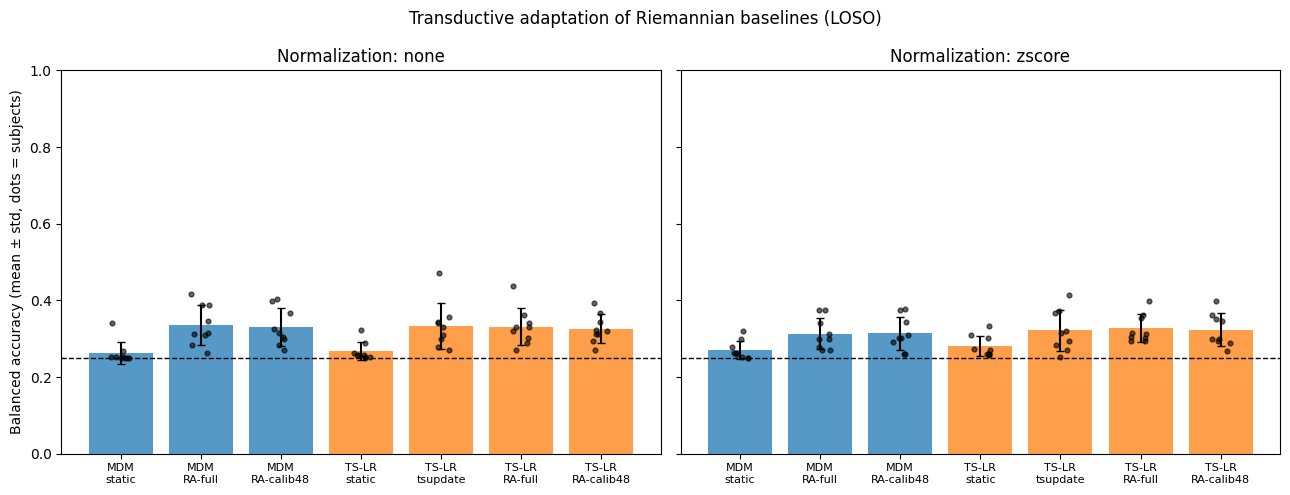

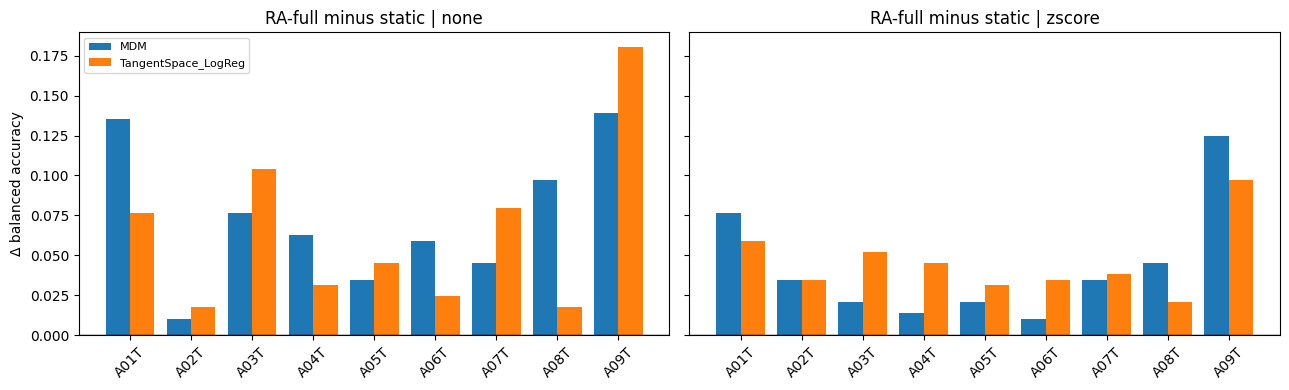

In [13]:
adapt_order = list(ADAPTATIONS.keys())
fig, axes = plt.subplots(1, len(NORMALIZATIONS), figsize=(13, 5), sharey=True)
conds = [(m, a) for m in MODELS for a in adapt_order if m in ADAPTATIONS[a]["models"]]
rng = np.random.default_rng(0)

for ax, norm in zip(np.atleast_1d(axes), NORMALIZATIONS):
    means, stds, tick = [], [], []
    for k, (m, a) in enumerate(conds):
        vals = per_subject[(norm, m, a)].values
        means.append(vals.mean()); stds.append(vals.std(ddof=1))
        ax.scatter(k + rng.uniform(-0.12, 0.12, len(vals)), vals, color="k", s=12, zorder=3, alpha=0.6)
        tick.append(f"{'MDM' if m == 'MDM' else 'TS-LR'}\n{a}")
    ax.bar(range(len(conds)), means, yerr=stds, capsize=3, alpha=0.75,
           color=["C0" if m == "MDM" else "C1" for m, _ in conds])
    ax.axhline(0.25, color="k", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(conds)))
    ax.set_xticklabels(tick, fontsize=8)
    ax.set_title(f"Normalization: {norm}")
    ax.set_ylim(0, 1)
np.atleast_1d(axes)[0].set_ylabel("Balanced accuracy (mean ± std, dots = subjects)")
plt.suptitle("Transductive adaptation of Riemannian baselines (LOSO)")
plt.tight_layout()
plt.savefig("saved_plots/Riemannian_transductive_LOSO.png", dpi=200)
plt.show()

# Per-subject gain of full recentering over static, for the two models
fig, axes = plt.subplots(1, len(NORMALIZATIONS), figsize=(13, 4), sharey=True)
x = np.arange(len(ALL_SUBJECTS))
for ax, norm in zip(np.atleast_1d(axes), NORMALIZATIONS):
    for k, m in enumerate(MODELS):
        gain = (per_subject[(norm, m, "RA-full")] - per_subject[(norm, m, "static")]).reindex(ALL_SUBJECTS)
        ax.bar(x + (k - 0.5) * 0.4, gain.values, 0.4, label=m)
    ax.axhline(0, color="k", linewidth=1)
    ax.set_xticks(x); ax.set_xticklabels(ALL_SUBJECTS, rotation=45)
    ax.set_title(f"RA-full minus static | {norm}")
np.atleast_1d(axes)[0].set_ylabel("Δ balanced accuracy")
np.atleast_1d(axes)[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("saved_plots/Riemannian_RA_gain_per_subject.png", dpi=200)
plt.show()

## Comparison with the neural networks (read with care)
Rename the neural LOSO tables (both notebooks write `loso_results.csv`) to `loso_results_eegnet.csv` and `loso_results_attention.csv`, or edit the paths below. Missing files are skipped.

Reading rules:
- **`static` Riemannian rows vs neural**: both inductive, a fair comparison.
- **`tsupdate` / `RA-*` rows vs neural**: the Riemannian side uses unlabeled target-subject data at inference, the neural side does not. A better score here shows the value of target-domain unlabeled data, not that the Riemannian representation is better. Report these as *transductive* results.
- The Riemannian variant taken as reference is selected by **mean validation balanced accuracy among the inductive (`static`) variants** and, separately, among **all** variants including transductive ones. Test results are never used for selection.

In [14]:
NEURAL_FILES = {
    "EEGNet": "loso_results_notebook_8.csv",
    "AttentionBaseNet": "loso_results_notebook_9.csv",
}

def label(r):
    return f"{r['Model']} | {r['Normalization']} | {r['Adaptation']}"

results_df["System"] = results_df.apply(label, axis=1)
val_means = results_df.groupby("System")["Val Balanced Accuracy"].mean()
inductive = results_df[results_df["Adaptation"] == "static"]["System"].unique()
ref_inductive = val_means[inductive].idxmax()
ref_all = val_means.idxmax()
print(f"Best inductive variant by validation:           {ref_inductive} (val BA = {val_means[ref_inductive]:.3f})")
print(f"Best variant overall (incl. transductive):      {ref_all} (val BA = {val_means[ref_all]:.3f})\n")

rows = [{"System": r["System"], "Family": "Riemannian",
         "Test Subject": r["Test Subject"], "Balanced Accuracy": r["Balanced Accuracy"]}
        for _, r in results_df.iterrows()]
neural_found = []
for net, path in NEURAL_FILES.items():
    if not os.path.exists(path):
        print(f"[skip] {path} not found ({net})")
        continue
    ndf = pd.read_csv(path)
    for _, r in ndf.iterrows():
        rows.append({"System": f"{net} | {r['Condition']}", "Family": "Neural (inductive)",
                     "Test Subject": r["Test Subject"], "Balanced Accuracy": r["Balanced Accuracy"]})
    neural_found.append(net)

comp = pd.DataFrame(rows)
comp_pivot = comp.pivot(index="Test Subject", columns="System", values="Balanced Accuracy")
fam = comp.drop_duplicates("System").set_index("System")["Family"]

if neural_found:
    print("=== Mean ± std balanced accuracy across 9 test subjects ===")
    display(comp.groupby(["Family", "System"])["Balanced Accuracy"].agg(["mean", "std"]).round(3))

    neural_systems = [s for s in comp_pivot.columns if fam[s].startswith("Neural")]
    for title, ref in [("inductive reference", ref_inductive), ("overall reference (transductive allowed)", ref_all)]:
        print(f"\n=== Paired difference: {ref} [{title}] minus each neural system (exploratory) ===")
        for s in neural_systems:
            d = (comp_pivot[ref] - comp_pivot[s]).dropna()
            line = f"{s:30s} mean delta = {d.mean():+.3f} | Riemannian better in {(d > 0).sum()}/{len(d)} subjects"
            if len(d) > 5 and not (d == 0).all():
                line += f" | Wilcoxon p = {wilcoxon(d)[1]:.4f}"
            print(line)
else:
    print("No neural result file found: comparison skipped.")

Best inductive variant by validation:           TangentSpace_LogReg | zscore | static (val BA = 0.286)
Best variant overall (incl. transductive):      MDM | none | RA-full (val BA = 0.342)

[skip] loso_results_notebook_9.csv not found (AttentionBaseNet)
=== Mean ± std balanced accuracy across 9 test subjects ===


mean    std
Family             System                                                 
Neural (inductive) EEGNet | Aug                               0.540  0.100
                   EEGNet | NoAug                             0.532  0.093
Riemannian         MDM | none | RA-calib48                    0.330  0.049
                   MDM | none | RA-full                       0.336  0.052
                   MDM | none | static                        0.263  0.029
                   MDM | zscore | RA-calib48                  0.314  0.044
                   MDM | zscore | RA-full                     0.313  0.041
                   MDM | zscore | static                      0.271  0.024
                   TangentSpace_LogReg | none | RA-calib48    0.326  0.037
                   TangentSpace_LogReg | none | RA-full       0.331  0.048
                   TangentSpace_LogReg | none | static        0.267  0.024
                   TangentSpace_LogReg | none | tsupdate      0.333  0.060
                   TangentSpace_LogReg | zscore | RA-calib48  0.323  0.043
                   TangentSpace_LogReg | zscore | RA-full     0.327  0.036
                   TangentSpace_LogReg | zscore | static      0.281  0.027
                   TangentSpace_LogReg | zscore | tsupdate    0.321  0.053


=== Paired difference: TangentSpace_LogReg | zscore | static [inductive reference] minus each neural system (exploratory) ===
EEGNet | Aug                   mean delta = -0.259 | Riemannian better in 0/9 subjects | Wilcoxon p = 0.0039
EEGNet | NoAug                 mean delta = -0.252 | Riemannian better in 0/9 subjects | Wilcoxon p = 0.0039

=== Paired difference: MDM | none | RA-full [overall reference (transductive allowed)] minus each neural system (exploratory) ===
EEGNet | Aug                   mean delta = -0.204 | Riemannian better in 0/9 subjects | Wilcoxon p = 0.0039
EEGNet | NoAug                 mean delta = -0.196 | Riemannian better in 0/9 subjects | Wilcoxon p = 0.0039


## Limitations and reporting notes
- **Transductive by construction.** `tsupdate` and `RA-*` use unlabeled target-subject trials at inference. Always label these results as transductive and do not rank them against inductive neural networks as if the protocol were equal.
- **Offline vs online.** `RA-full` uses the whole target session, which is not available in an online BCI. `RA-calib48` is closer to a calibration scenario, but it still uses an unlabeled batch collected before decoding starts.
- **Class balance assumption.** Recentering with the mean of all target trials is unbiased with respect to class only if the session is roughly class-balanced, as it is in BCI IV-2a (72 trials per class). With strongly imbalanced sessions the mean would be pulled towards the majority class.
- **Calibration size.** Only one calibration size (48 trials) is evaluated. A sweep over sizes would be a further, separate analysis.
- **9 subjects, one dataset.** P-values are exploratory. Report per-subject changes, not only means.
- **Variant selection.** If one adaptation is carried forward, choose it by validation balanced accuracy (as above), not by the test means.
- **Not included.** No augmentation, no supervised/semi-supervised target adaptation, no neural-network adaptation.